In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import torch

sys.path.append(str(Path().resolve().parent / "src"))

from data import (
    GDPHMMPreprocessedSlicesDataset,
    GDPHMM_DOSE_MAX,
    GDPHMM_OAR,
    GDPHMM_OAR_V3
)

COLORS = {
    # --- Optics / Ear ---
    "Cochlea_L":        {"fill": "#99D9EA", "line": "#3399CC"},
    "Cochlea_R":        {"fill": "#66C2E0", "line": "#1F78B4"},
    "Eyes":             {"fill": "#B3CDE3", "line": "#4A6FA5"},
    "Lens_L":           {"fill": "#CCE5FF", "line": "#6699CC"},
    "Lens_R":           {"fill": "#BBD9FF", "line": "#4D88CC"},
    "OpticNerve_L":     {"fill": "#99CCFF", "line": "#3366CC"},
    "OpticNerve_R":     {"fill": "#66B2FF", "line": "#1F4FBF"},
    "Chiasm":           {"fill": "#80BFFF", "line": "#005FCC"},

    # --- Brain / CNS ---
    "Brain":            {"fill": "#D0D0D0", "line": "#808080"},
    "BrainStem_03":     {"fill": "#66FFFF", "line": "#00B3B3"},
    "SpinalCord_05":    {"fill": "#4DFFFF", "line": "#00A6A6"},

    # --- Airway / Digestive ---
    "Trachea":          {"fill": "#99E699", "line": "#339933"},
    "Esophagus":        {"fill": "#B2E6B2", "line": "#4CAF50"},
    "Larynx-PTV":       {"fill": "#FF99FF", "line": "#CC00CC"},

    # --- Thorax / Misc ---
    "Lungs":            {"fill": "#66CC99", "line": "#2E8B57"},
    "Posterior_Neck":   {"fill": "#C2B280", "line": "#8B7D3A"},
    "Shoulders":        {"fill": "#D8CFC4", "line": "#8C8273"},

    # --- Oral cavity / Jaw ---
    "Lips":             {"fill": "#FFB3B3", "line": "#CC6666"},
    "Mandible-PTV":     {"fill": "#FFB266", "line": "#CC7A00"},
    "OCavity-PTV":      {"fill": "#FF80BF", "line": "#CC0066"},

    # --- Salivary glands (PTV-related) ---
    "ParotidCon-PTV":   {"fill": "#FFB3D9", "line": "#CC3385"},
    "ParotidIps-PTV":   {"fill": "#FF99CC", "line": "#CC0066"},
    "Parotids-PTV":     {"fill": "#FF66B2", "line": "#B30059"},
    "Submand-PTV":      {"fill": "#FFCCE5", "line": "#CC6699"},
    "SubmandL-PTV":     {"fill": "#FFB3E6", "line": "#CC66B2"},
    "SubmandR-PTV":     {"fill": "#FF99D6", "line": "#B24C8C"},

    # --- Pharyngeal / Thyroid ---
    "PharConst-PTV":    {"fill": "#FF8CFF", "line": "#993399"},
    "Thyroid-PTV":      {"fill": "#E699FF", "line": "#9933CC"},
}

In [3]:
# Load dataset with all structure groups
dataset = GDPHMMPreprocessedSlicesDataset(
    dataset_name='gdphmm-hn-vmat',
    split='test',
    structure_groups=None  # Load all groups
)

# Find the specific volume and slice
volume_name = 'HNSCC-01-0078+A4Ac+MOS_12319'
slice_idx = 110

# Find the index in the dataset
matching_indices = dataset.index[
    (dataset.index['volume'] == volume_name) &
    (dataset.index['slice_idx'] == slice_idx)
].index.tolist()

if not matching_indices:
    raise ValueError(f"Volume {volume_name} slice {slice_idx} not found")

idx = matching_indices[0]
print(f"Found at dataset index: {idx}")

Found at dataset index: 7692


In [4]:
# Load the slice and extract all components
structure, dose, info = dataset[idx]
print(structure.shape, dose.shape)

structure = torch.flip(structure, dims=[1, 2])
dose = torch.flip(dose, dims=[1, 2])

# Extract individual components using the selector
ct = dataset.selector.get_component(structure, 'ct')[0].numpy()  # (H, W)
body = dataset.selector.get_component(structure, 'body')[0].numpy()  # (H, W)
ptv_doses = dataset.selector.get_component(structure, 'ptv_doses').numpy()  # (3, H, W)
ptv_sdm = dataset.selector.get_component(structure, 'ptv_sdm').numpy()  # (3, H, W)
oar_sdm = dataset.selector.get_component(structure, 'oar_sdm').numpy()  # (33, H, W)
oar_masks = dataset.selector.get_component(structure, 'oar_v3').numpy()  # (33, H, W)
beam_plate = dataset.selector.get_component(structure, 'beam_plate')[0].numpy()  # (H, W)
angle_plate = dataset.selector.get_component(structure, 'angle_plate')[0].numpy()  # (H, W)
gt_dose = dose[0].numpy()  # (H, W)

print(f"CT shape: {ct.shape}, range: [{ct.min():.3f}, {ct.max():.3f}]")
print(f"Body shape: {body.shape}, unique: {np.unique(body)}")
print(f"PTV Doses shape: {ptv_doses.shape}, range: [{ptv_doses.min():.3f}, {ptv_doses.max():.3f}]")
print(f"PTV SDM shape: {ptv_sdm.shape}, range: [{ptv_sdm.min():.3f}, {ptv_sdm.max():.3f}]")
print(f"OAR SDM shape: {oar_sdm.shape}, range: [{oar_sdm.min():.3f}, {oar_sdm.max():.3f}]")
print(f"OAR Masks shape: {oar_masks.shape}, unique: {np.unique(oar_masks)}")
print(f"Beam Plate shape: {beam_plate.shape}, range: [{beam_plate.min():.3f}, {beam_plate.max():.3f}]")
print(f"Angle Plate shape: {angle_plate.shape}, unique: {np.unique(angle_plate)}")
print(f"GT Dose shape: {gt_dose.shape}, range: [{gt_dose.min():.3f}, {gt_dose.max():.3f}]")

torch.Size([192, 176, 160]) torch.Size([1, 176, 160])
CT shape: (176, 160), range: [0.000, 0.709]
Body shape: (176, 160), unique: [0. 1.]
PTV Doses shape: (3, 176, 160), range: [0.000, 0.818]
PTV SDM shape: (3, 176, 160), range: [-1.000, 0.200]
OAR SDM shape: (33, 176, 160), range: [0.000, 0.852]
OAR Masks shape: (28, 176, 160), unique: [0. 1.]
Beam Plate shape: (176, 160), range: [0.000, 0.982]
Angle Plate shape: (176, 160), unique: [0.]
GT Dose shape: (176, 160), range: [0.000, 0.854]


In [5]:
# Debug: check angle plate values
print(f"Angle Plate - min: {angle_plate.min()}, max: {angle_plate.max()}, unique: {np.unique(angle_plate)}")
print(f"Angle Plate has content: {angle_plate.any()}")

if not angle_plate.any():
    # Find a slice with angle plate data for this volume
    print("\nAngle plate is empty for this slice (only exists ±5 slices from isocenter)")
    print("Searching for slices with angle plate data...")
    volume_slices = dataset.index[dataset.index['volume'] == volume_name]
    for test_idx in volume_slices.index[:]:
        test_structure, _, test_info = dataset[test_idx]
        test_angle = dataset.selector.get_component(test_structure, 'angle_plate')[0].numpy()
        if test_angle.any():
            print(f"  Found angle plate at slice {test_info['index']}")
            break
    else:
        print("  No slices with angle plate found")

Angle Plate - min: 0.0, max: 0.0, unique: [0.]
Angle Plate has content: False

Angle plate is empty for this slice (only exists ±5 slices from isocenter)
Searching for slices with angle plate data...
  Found angle plate at slice 59


In [6]:
# Compute global SDM range for consistent color scale (centered at 0)
all_sdm = np.concatenate([ptv_sdm, oar_sdm], axis=0)
sdm_abs_max = max(abs(all_sdm.min()), abs(all_sdm.max()))
sdm_vmin, sdm_vmax = -sdm_abs_max, sdm_abs_max
print(f"SDM range: [{sdm_vmin:.3f}, {sdm_vmax:.3f}]")

SDM range: [-1.000, 1.000]


OCavity-PTV {'fill': '#FF80BF', 'line': '#CC0066'}


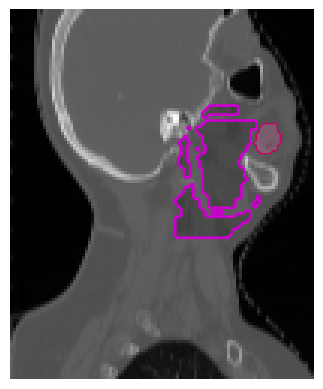

In [7]:
# Structure
PTV_FILL = "#0F0F0F"    # light magenta
PTV_LINE = "#CC00CC"    # darker magenta


ys, xs = np.where(body)

ymin, ymax = ys.min(), ys.max()
xmin, xmax = xs.min(), xs.max()

ct_cropped = ct[ymin:ymax+1, xmin:xmax+1]
mask_cropped = body[ymin:ymax+1, xmin:xmax+1]

fig, ax = plt.subplots()
ax.imshow(ct_cropped, cmap='gray', interpolation='nearest')

for oar_name, oar_mask in zip(GDPHMM_OAR_V3, oar_masks):
    if oar_mask.any():
      if oar_name == 'OCavity-PTV':
        oar_mask = oar_mask[ymin:ymax+1, xmin:xmax+1] > 0

        cord_overlay = np.ma.masked_where(~oar_mask, oar_mask)

        color = COLORS[oar_name]
        CORD_FILL = color['fill']
        CORD_LINE = color['line']

        print(oar_name, color)

        ax.imshow(
            cord_overlay,
            cmap=ListedColormap([CORD_FILL]),
            alpha=0.25,
            interpolation="nearest"
        )

        ax.contour(
            oar_mask,
            levels=[0.5],
            colors=[CORD_LINE],
            linewidths=1
        )

ptv_masks = np.sum(ptv_doses > 0, axis=0) > 0  # Combine all PTV masks into one
ptv_masks = ptv_masks[ymin:ymax+1, xmin:xmax+1] > 0
ptv_overlay = np.ma.masked_where(~ptv_masks, ptv_masks)

ax.imshow(
  ptv_overlay,
  cmap=ListedColormap([PTV_FILL]),
  alpha=0.25,
  interpolation="nearest"
)

ax.contour(
  ptv_masks,
  levels=[0.5],
  colors=[PTV_LINE],
  linewidths=2
)

ax.axis('off')
ax.margins(0, 0)
plt.savefig('../imgs/structure.png', bbox_inches='tight', pad_inches=0)
plt.show()

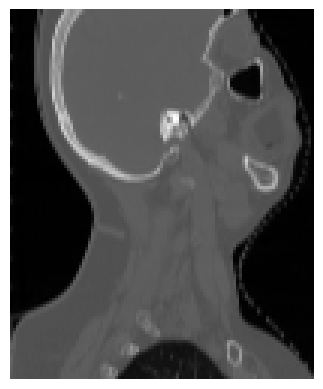

In [24]:
# CT

ys, xs = np.where(body)

ymin, ymax = ys.min(), ys.max()
xmin, xmax = xs.min(), xs.max()

ct_cropped = ct[ymin:ymax+1, xmin:xmax+1]

plt.figure()
plt.imshow(ct_cropped, cmap='gray')
plt.axis('off')
plt.margins(0, 0)
plt.savefig('../imgs/ct.png', bbox_inches='tight', pad_inches=0)
plt.show()

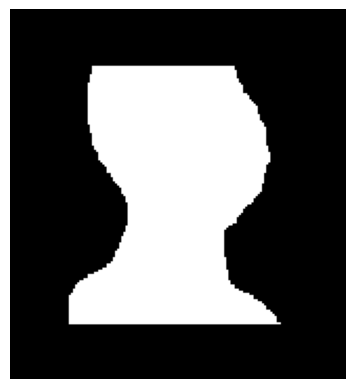

In [9]:
# Body Mask
plt.figure()
plt.imshow(body, cmap='gray')
plt.axis('off')
plt.margins(0, 0)
plt.savefig('../imgs/body_mask.png', bbox_inches='tight', pad_inches=0)
plt.show()

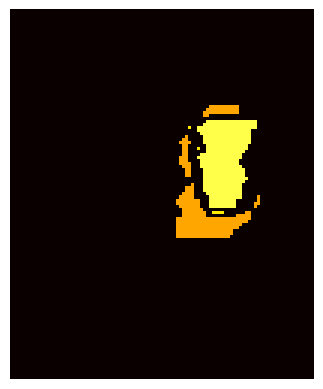

In [25]:
# PTV Combined Dose

ptv_dose = ptv_doses[0] + ptv_doses[1] + ptv_doses[2]

ys, xs = np.where(body)

ymin, ymax = ys.min(), ys.max()
xmin, xmax = xs.min(), xs.max()

ptv_dose_cropped = ptv_dose[ymin:ymax+1, xmin:xmax+1]

plt.figure()
plt.imshow(ptv_dose_cropped * GDPHMM_DOSE_MAX, cmap='hot', vmin=0, vmax=GDPHMM_DOSE_MAX)
plt.axis('off')
plt.margins(0, 0)
plt.savefig('../imgs/ptv_combined.png', bbox_inches='tight', pad_inches=0)
plt.show()

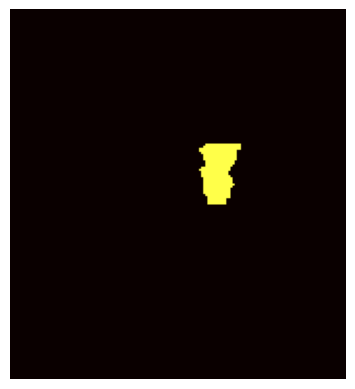

In [10]:
# PTV Dose High
plt.figure()
plt.imshow(ptv_doses[0] * GDPHMM_DOSE_MAX, cmap='hot', vmin=0, vmax=GDPHMM_DOSE_MAX)
plt.axis('off')
plt.margins(0, 0)
plt.savefig('../imgs/ptv_dose_high.png', bbox_inches='tight', pad_inches=0)
plt.show()

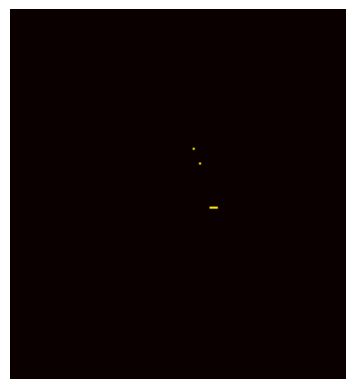

In [11]:
# PTV Dose Mid
plt.figure()
plt.imshow(ptv_doses[1] * GDPHMM_DOSE_MAX, cmap='hot', vmin=0, vmax=GDPHMM_DOSE_MAX)
plt.axis('off')
plt.margins(0, 0)
plt.savefig('../imgs/ptv_dose_mid.png', bbox_inches='tight', pad_inches=0)
plt.show()

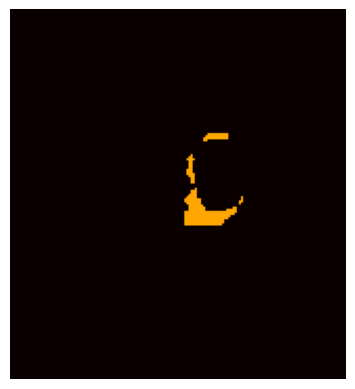

In [12]:
# PTV Dose Low
plt.figure()
plt.imshow(ptv_doses[2] * GDPHMM_DOSE_MAX, cmap='hot', vmin=0, vmax=GDPHMM_DOSE_MAX)
plt.axis('off')
plt.margins(0, 0)
plt.savefig('../imgs/ptv_dose_low.png', bbox_inches='tight', pad_inches=0)
plt.show()

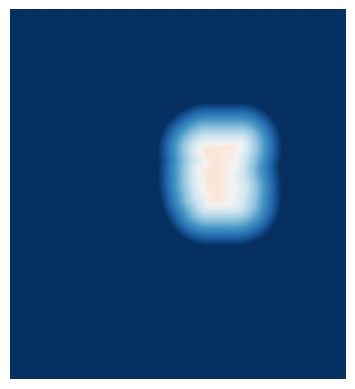

In [13]:
# PTV SDM High
plt.figure()
plt.imshow(ptv_sdm[0], cmap='RdBu_r', vmin=sdm_vmin, vmax=sdm_vmax)
plt.axis('off')
plt.margins(0, 0)
plt.savefig('../imgs/ptv_sdm_high.png', bbox_inches='tight', pad_inches=0)
plt.show()

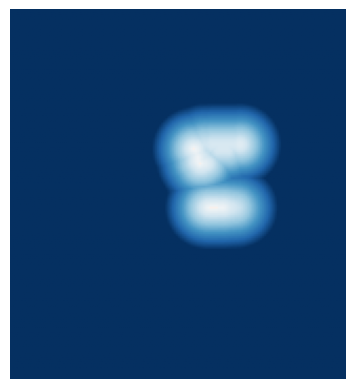

In [14]:
# PTV SDM Mid
plt.figure()
plt.imshow(ptv_sdm[1], cmap='RdBu_r', vmin=sdm_vmin, vmax=sdm_vmax)
plt.axis('off')
plt.margins(0, 0)
plt.savefig('../imgs/ptv_sdm_mid.png', bbox_inches='tight', pad_inches=0)
plt.show()

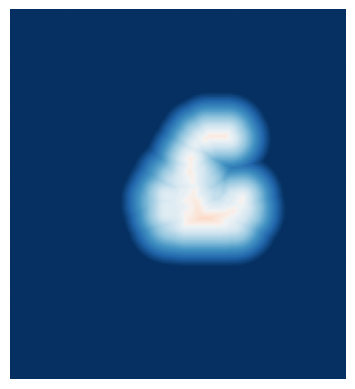

In [ ]:
# PTV SDM Low
plt.figure()
plt.imshow(ptv_sdm[2], cmap='RdBu_r', vmin=sdm_vmin, vmax=sdm_vmax)
plt.axis('off')
plt.margins(0, 0)
plt.savefig('../imgs/ptv_sdm_low.png', bbox_inches='tight', pad_inches=0)
plt.show()

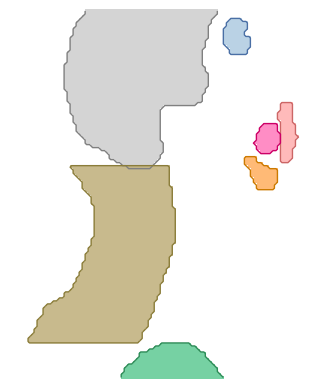

In [39]:
# OAR Combined

plt.figure()

for oar_name, oar_mask in zip(GDPHMM_OAR_V3, oar_masks):
    if oar_mask.any():
        oar_mask = oar_mask[ymin:ymax+1, xmin:xmax+1] > 0

        cord_overlay = np.ma.masked_where(~oar_mask, oar_mask)

        color = COLORS[oar_name]
        CORD_FILL = color['fill']
        CORD_LINE = color['line']

        plt.imshow(
            cord_overlay,
            cmap=ListedColormap([CORD_FILL]),
            alpha=0.9,
            interpolation="nearest"
        )

        plt.contour(
            oar_mask,
            levels=[0.5],
            colors=[CORD_LINE],
            linewidths=1
        )
plt.axis('off')
plt.margins(0, 0)
plt.savefig(f'../imgs/oar_combined.png', bbox_inches='tight', pad_inches=0)
plt.show()

In [16]:
# Prefer larger organs for visualization
preferred_oars = ['Brain', 'Posterior_Neck', 'BrainStem_03', 'Lungs', 'SpinalCord_05', 'Esophagus', 'Trachea', 'Mandible-PTV', 'Larynx-PTV']

oars_with_contour = []
# First try preferred large organs
for oar_name in preferred_oars:
    if oar_name in GDPHMM_OAR:
        i = GDPHMM_OAR.index(oar_name)
        if oar_sdm[i].min() != oar_sdm[i].max():
            oars_with_contour.append((i, oar_name))
        if len(oars_with_contour) >= 3:
            break

# Fall back to any OAR with contour if needed
if len(oars_with_contour) < 3:
    for i, oar_name in enumerate(GDPHMM_OAR):
        if (i, oar_name) not in oars_with_contour and oar_sdm[i].min() != oar_sdm[i].max():
            oars_with_contour.append((i, oar_name))
        if len(oars_with_contour) >= 3:
            break

print(f"Selected OARs: {[name for _, name in oars_with_contour]}")

Selected OARs: ['Brain', 'Posterior_Neck', 'Lungs']


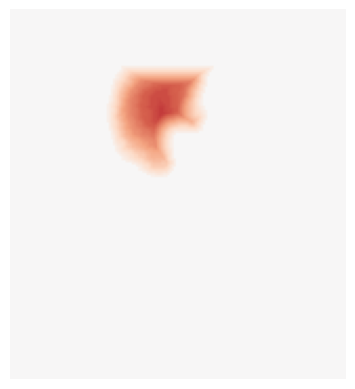

In [17]:
# OAR SDM 1
oar_idx, oar_name = oars_with_contour[0]
plt.figure()
plt.imshow(oar_sdm[oar_idx], cmap='RdBu_r', vmin=sdm_vmin, vmax=sdm_vmax)
plt.axis('off')
plt.margins(0, 0)
plt.savefig(f'../imgs/oar_sdm_{oar_name}.png', bbox_inches='tight', pad_inches=0)
plt.show()

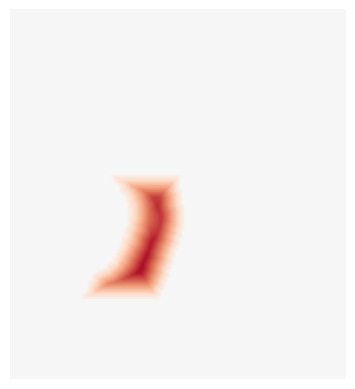

In [18]:
# OAR SDM 2
oar_idx, oar_name = oars_with_contour[1]
plt.figure()
plt.imshow(oar_sdm[oar_idx], cmap='RdBu_r', vmin=sdm_vmin, vmax=sdm_vmax)
plt.axis('off')
plt.margins(0, 0)
plt.savefig(f'../imgs/oar_sdm_{oar_name}.png', bbox_inches='tight', pad_inches=0)
plt.show()

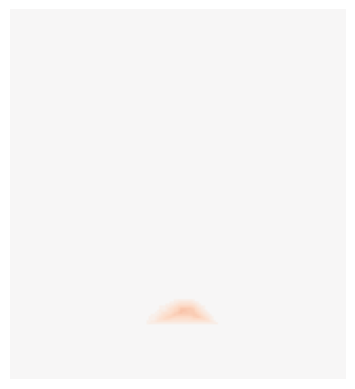

In [19]:
# OAR SDM 3
oar_idx, oar_name = oars_with_contour[2]
plt.figure()
plt.imshow(oar_sdm[oar_idx], cmap='RdBu_r', vmin=sdm_vmin, vmax=sdm_vmax)
plt.axis('off')
plt.margins(0, 0)
plt.savefig(f'../imgs/oar_sdm_{oar_name}.png', bbox_inches='tight', pad_inches=0)
plt.show()

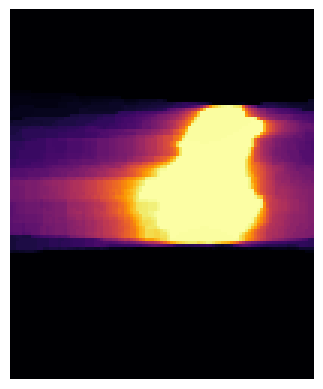

In [20]:
# Beam Plate

ys, xs = np.where(body)

ymin, ymax = ys.min(), ys.max()
xmin, xmax = xs.min(), xs.max()

beam_plate_cropped = beam_plate[ymin:ymax+1, xmin:xmax+1]

plt.figure()
plt.imshow(beam_plate_cropped, cmap='inferno')
plt.axis('off')
plt.margins(0, 0)
plt.savefig('../imgs/beam_plate.png', bbox_inches='tight', pad_inches=0)
plt.show()

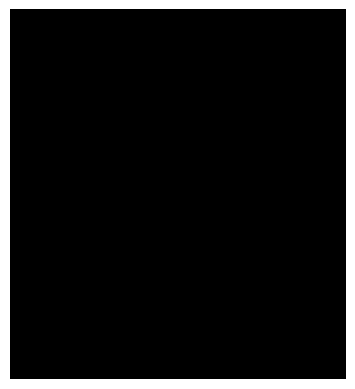

In [21]:
# Angle Plate
plt.figure()
plt.imshow(angle_plate, cmap='gray')
plt.axis('off')
plt.margins(0, 0)
plt.savefig('../imgs/angle_plate.png', bbox_inches='tight', pad_inches=0)
plt.show()

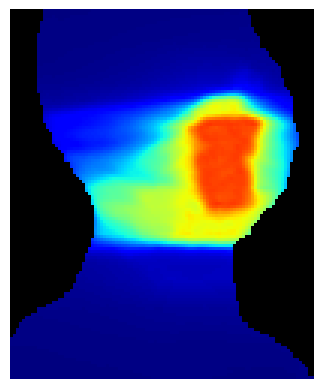

In [22]:
# GT Dose
cmap = plt.cm.jet.copy()
cmap.set_bad(color='black')

ys, xs = np.where(body)

ymin, ymax = ys.min(), ys.max()
xmin, xmax = xs.min(), xs.max()

dose_cropped = dose[0, ymin:ymax+1, xmin:xmax+1]
mask_cropped = body[ymin:ymax+1, xmin:xmax+1]

dose_masked = np.ma.array(dose_cropped * GDPHMM_DOSE_MAX, mask=~mask_cropped.astype(bool))

plt.figure()
plt.imshow(dose_masked, cmap=cmap, vmin=0, vmax=GDPHMM_DOSE_MAX)
plt.axis('off')
plt.margins(0, 0)
plt.savefig('../imgs/gt_dose.png', bbox_inches='tight', pad_inches=0)
plt.show()

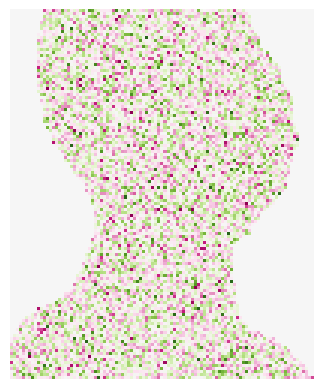

In [23]:
noise = np.random.randn(*gt_dose.shape) * body
noise = noise[ymin:ymax+1, xmin:xmax+1]

plt.figure()
plt.imshow(noise, cmap='PiYG', vmin=-3, vmax=3)
plt.axis('off')
plt.margins(0, 0)
plt.savefig('../imgs/noise.png', bbox_inches='tight', pad_inches=0)
plt.show()